# code_222 · A drift alert is an investigation trigger

**Book:** section 42.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_42_GUIDE.md), [execution evidence](../CHAPTER_42_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_222).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Monitoring separates observable inputs, historical predictions, delayed outcome maturity, selection mechanisms, operational versions and authority to update. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8022;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8022


## Separate a seasonal nuisance feature from a changed response law
 Generate a previous52-week reference year and a current52-week monitoring year with100 independent records per week. Temperature has a repeating sinusoidal mean and does not determine the response; severity does. Fit a logistic model on previous-year severity only. During current weeks32–51, reverse the severity-response relation while leaving feature distributions unchanged. This is a known simulator change, not an inferred diagnosis. Test each current temperature sample against pooled reference temperature and against its same-phase reference week using actual two-sample KS tests. Test severity against pooled reference severity too. The family for each temperature route has52 predeclared weekly looks; show nominal0.05 and Bonferroni0.05/52 decisions. A matching seasonal reference changes the null question and requires reliable phase alignment.


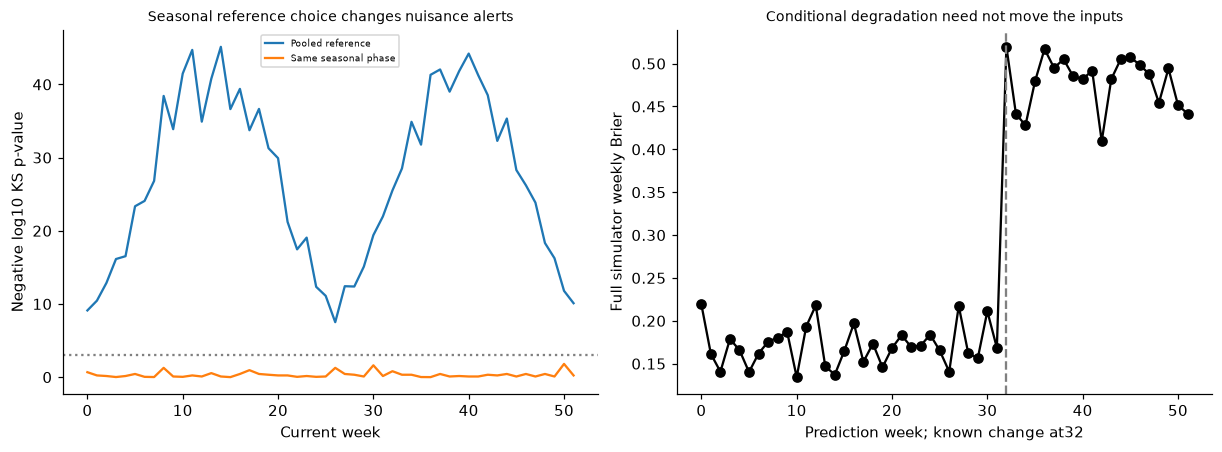

In [2]:
from sklearn.linear_model import LogisticRegression
from scipy.stats import ks_2samp
weeks=np.repeat(np.arange(52),100);phase=np.sin(2*np.pi*weeks/52);reference_temp=1.8*phase+rng.normal(scale=.5,size=5200);current_temp=1.8*phase+rng.normal(scale=.5,size=5200);reference_x=rng.normal(size=5200);current_x=rng.normal(size=5200);reference_y=rng.binomial(1,expit(1.5*reference_x));current_y=rng.binomial(1,expit(np.where(weeks>=32,-1.5,1.5)*current_x));model=LogisticRegression(C=1).fit(reference_x[:,None],reference_y);p=model.predict_proba(current_x[:,None])[:,1];tests=[]
for w in range(52):
    mask=weeks==w;tests.append({'week':w,'pooled_temperature_p':float(ks_2samp(reference_temp,current_temp[mask]).pvalue),'phase_temperature_p':float(ks_2samp(reference_temp[mask],current_temp[mask]).pvalue),'severity_p':float(ks_2samp(reference_x,current_x[mask]).pvalue),'Brier':float(np.mean((p[mask]-current_y[mask])**2)),'mean_prediction':float(p[mask].mean())})
pooled=np.array([r['pooled_temperature_p'] for r in tests]);matched=np.array([r['phase_temperature_p'] for r in tests]);briers=np.array([r['Brier'] for r in tests]);assert len(tests)==52 and np.all(np.isfinite(briers));RESULTS.update(reference_rows=5200,current_rows=5200,changed_conditional_week=32,weekly_temperature_looks=52,pooled_temperature_nominal_alerts=int(np.sum(pooled<.05)),phase_matched_temperature_nominal_alerts=int(np.sum(matched<.05)),pooled_temperature_Bonferroni_alerts=int(np.sum(pooled<.05/52)),phase_matched_temperature_Bonferroni_alerts=int(np.sum(matched<.05/52)),prechange_Brier=float(np.mean((p[weeks<32]-current_y[weeks<32])**2)),changed_Brier=float(np.mean((p[weeks>=32]-current_y[weeks>=32])**2)),prediction_mean_prechange=float(p[weeks<32].mean()),prediction_mean_changed=float(p[weeks>=32].mean()),temperature_is_response_irrelevant=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(range(52),-np.log10(np.maximum(pooled,1e-100)),label='Pooled reference');axes[0].plot(range(52),-np.log10(np.maximum(matched,1e-100)),label='Same seasonal phase');axes[0].axhline(-np.log10(.05/52),color='.5',linestyle=':');axes[0].set(xlabel='Current week',ylabel='Negative log10 KS p-value',title='Seasonal reference choice changes nuisance alerts');axes[0].legend(fontsize=6);axes[1].plot(range(52),briers,'o-',color='black');axes[1].axvline(32,color='.5',linestyle='--');axes[1].set(xlabel='Prediction week; known change at32',ylabel='Full simulator weekly Brier',title='Conditional degradation need not move the inputs');plt.show()


## Audit repeated alerts rather than treating each nominal p-value as a yearly guarantee
 Simulate2,000 monitoring years of52 independent Uniform[0,1] null p-values. This is an explicit calibrated-independent-p-value control, not a simulation of dependent KS windows. Compare the probability of any nominal alert with1−0.95^52 and the fixed-family Bonferroni control. The union bound does not require independence if every individual null p-value is valid; infinite repeated looks, selection or dependent invalid p-values need additional reasoning. A three-week label delay shifts the availability of Brier evidence. Record when the frozen Brier threshold0.30 is first observable after the known change, without using this result to optimize the threshold. These finite-window experiments implement neither ADWIN nor an anytime-valid detector.


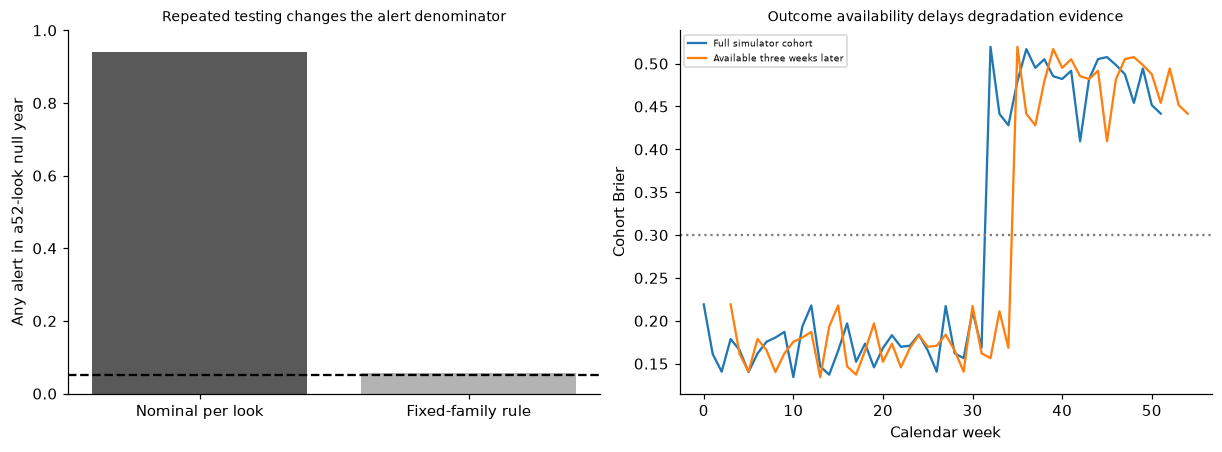

In [3]:
nullp=rng.uniform(size=(2000,52));nominal=float(np.mean(np.any(nullp<.05,axis=1)));family=float(np.mean(np.any(nullp<.05/52,axis=1)));theory=1-.95**52;assert abs(nominal-theory)<.04 and family<.08;quality_alerts=np.flatnonzero((np.arange(52)>=32)&(briers>.30));first_available=int(quality_alerts[0]+3) if len(quality_alerts) else None;assert first_available is None or first_available>=35;RESULTS.update(null_years=2000,null_p_values_assumed_independent_uniform=True,probability_any_nominal_null_alert=nominal,analytic_independent_nominal_family_probability=theory,probability_any_Bonferroni_null_alert=family,quality_label_delay_weeks=3,first_changed_quality_alert_available_week=first_available,quality_threshold_fixed=.30,ADWIN_implemented=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Nominal per look','Fixed-family rule'],[nominal,family],color=['.35','.7']);axes[0].axhline(.05,color='black',linestyle='--');axes[0].set(ylabel='Any alert in a52-look null year',ylim=(0,1),title='Repeated testing changes the alert denominator');axes[1].plot(range(52),briers,label='Full simulator cohort');axes[1].plot(np.arange(52)+3,briers,label='Available three weeks later');axes[1].axhline(.30,color='.5',linestyle=':');axes[1].set(xlabel='Calendar week',ylabel='Cohort Brier',title='Outcome availability delays degradation evidence');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_222','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pooled-reference and season-matched two-sample distribution tests', 'same-feature conditional response change with stable prediction distribution but degraded Brier', 'predeclared fixed-family Bonferroni thresholds and independent-uniform null monitoring simulation', 'delayed quality evidence separated from nuisance seasonal input alerts'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pooled-reference and season-matched two-sample distribution tests", "same-feature conditional response change with stable prediction distribution but degraded Brier", "predeclared fixed-family Bonferroni thresholds and independent-uniform null monitoring simulation", "delayed quality evidence separated from nuisance seasonal input alerts"], "elapsed_seconds": 0.441, "example_id": "code_222", "hardware": "Darwin arm64 CPU", "results": {"ADWIN_implemented": false, "analytic_independent_nominal_family_probability": 0.9305571598127664, "changed_Brier": 0.4788300383660915, "changed_conditional_week": 32, "current_rows": 5200, "first_changed_quality_alert_available_week": 35, "null_p_values_assumed_independent_uniform": true, "null_years": 2000, "phase_matched_temperature_Bonferroni_alerts": 0, "phase_matched_temperature_nominal_alerts": 2, "pooled_temperature_Bonferroni_alerts": 52, "pooled_temperature_nominal_alerts": 52, "prechange